# 08 · Geometric error model and out-of-plane tilt (paper Sec. *Geometric sensitivity*, Eq. *tilt_error*, *tilt_fit*)

1. The analytic scale error from out-of-plane tilt, Δs/s ≈ 1/cos φ − 1 (paper Eq. *tilt_error*).
2. The empirical fit MAE(φ) = w₀ + k(1 − cos φ) from the revision draft (Eq. *tilt_fit*), reproduced exactly.
3. ⚠ Why that fit should be redone: the captures it uses are **in-plane** rotations.

| | |
|---|---|
| **Inputs** | `data/raw/robustness/` |
| **Outputs** | `results/figures/fig_tilt_error.png`, `fig_tilt_fit.png`; `results/tables/tilt_error.csv`, `tilt_fit.csv` |
| **Runtime** | ~15 s |

In [1]:
%matplotlib inline
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import visioncrack as vc
from visioncrack import io
np.set_printoptions(precision=3, suppress=True)
pd.set_option('display.width', 200)
print('visioncrack', vc.__version__, '| numpy', np.__version__, '| pandas', pd.__version__)
FIG = io.results_dir('figures'); TAB = io.results_dir('tables')

visioncrack 0.1.0 | numpy 2.2.6 | pandas 2.3.0


## 1 · Analytic model

In [2]:
from visioncrack.error_model import tilt_scale_error, fit_tilt_model
phi = np.array([1, 2, 5, 10, 15, 20])
model = pd.DataFrame({'phi_deg': phi, 'exact_%': 100 * tilt_scale_error(phi),
                      'approx_phi2/2_%': 100 * tilt_scale_error(phi, exact=False)})
model['ET-1 error (mm)'] = 0.55 * model['exact_%'] / 100
model['ET-5 error (mm)'] = 2.75 * model['exact_%'] / 100
model.to_csv(TAB / 'tilt_error.csv', index=False)
# values quoted in the manuscript: 2° ≈ 0.06 %, 5° ≈ 0.38 %, 10° ≈ 1.5 %
assert [round(v, 2) for v in model.set_index('phi_deg').loc[[2, 5], 'exact_%']] == [0.06, 0.38]
assert round(model.set_index('phi_deg').loc[10, 'exact_%'], 1) == 1.5
model.round(4)

,phi_deg,exact_%,approx_phi2/2_%,ET-1 error (mm),ET-5 error (mm)
0,1,0.0152,0.0152,0.0001,0.0004
1,2,0.0610,0.0609,0.0003,0.0017
2,5,0.3820,0.3808,0.0021,0.0105
3,10,1.5427,1.5231,0.0085,0.0424
4,15,3.5276,3.4269,0.0194,0.0970
5,20,6.4178,6.0923,0.0353,0.1765


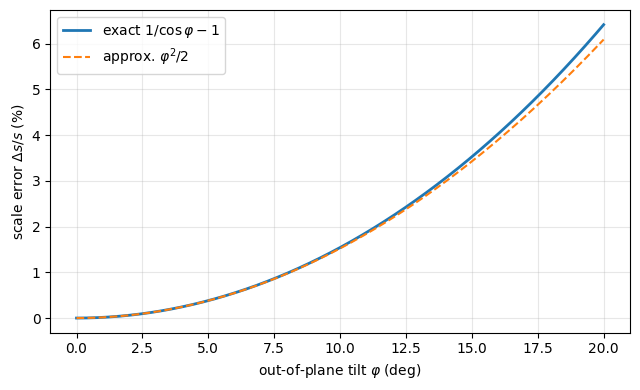

In [3]:
p = np.linspace(0, 20, 200)
plt.figure(figsize=(6.5, 4))
plt.plot(p, 100 * tilt_scale_error(p), lw=2, label=r'exact $1/\cos\varphi-1$')
plt.plot(p, 100 * tilt_scale_error(p, exact=False), '--', lw=1.5, label=r'approx. $\varphi^2/2$')
plt.xlabel(r'out-of-plane tilt $\varphi$ (deg)'); plt.ylabel(r'scale error $\Delta s/s$ (%)')
plt.grid(alpha=.3); plt.legend(); plt.tight_layout(); plt.savefig(FIG / 'fig_tilt_error.png', dpi=200); plt.show()

## 2 · Empirical fit, as in the revision draft

In [4]:
from visioncrack import sweep
res, ref = sweep.run_all()
A = res[res.folder.isin(['norm', 'roll']) & res.ref_found].copy()
A['tilt'] = np.where(A.folder == 'norm', 0.0, A.pose_a.abs())
tf = fit_tilt_model(A.tilt, A.ref_mae)
w0, k, r2, phi_c = tf.w0, tf.k, tf.r2, tf.phi_at(0.10)
fit = pd.DataFrame([{'w0_mm': w0, 'k_mm': k, 'R2': r2, 'phi_at_0.10mm_deg': phi_c, 'n': len(A)}])
fit.to_csv(TAB / 'tilt_fit.csv', index=False)
assert (round(w0, 4), round(k, 4), round(r2, 2), round(phi_c, 1)) == (0.0926, 0.2394, 0.89, 14.3)
print('✓ reproduces the draft: MAE = %.4f + %.4f(1 − cos φ), R² = %.2f, 0.10 mm at φ = %.1f°' % (w0, k, r2, phi_c))
fit.round(4)

✓ reproduces the draft: MAE = 0.0926 + 0.2394(1 − cos φ), R² = 0.89, 0.10 mm at φ = 14.3°


,w0_mm,k_mm,R2,phi_at_0.10mm_deg,n
0,0.0926,0.2394,0.8868,14.2664,16


## 3 · ⚠ What the fit actually measures

* The fitted captures are the old `angle` folder (now `roll/`). Their **measured in-plane rotation is ≈ 15° for every capture**.
  Out-of-plane tilt was not measured.
* The x-axis φ is `|pose_a|`, a phone **sensor** reading (12–78°). It is not the label's tilt and does not match the measured rotation (plot below).
* The out-of-plane captures (`pitch/`, `yaw/`) have **no resolvable reference bars** with this measurement chain, so they could not be fitted.

**Suggested fix before publishing:** (a) present this fit as *in-plane rotation without de-rotation*, or (b) measure φ from the
four detected corners (e.g. the ratio of opposite sides, as Sec. *Geometric sensitivity* proposes) on the pitch/yaw captures, and refit.

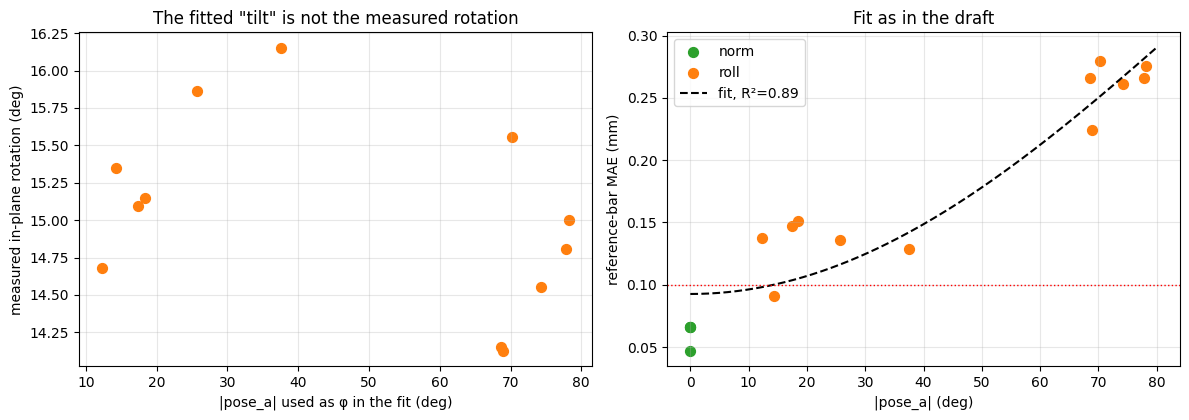

,inplane_deg,ref_found
folder,,
norm,0.44,1.0
dist,0.45,1.0
roll,15.04,1.0
pitch,0.87,0.0
yaw,1.81,0.0


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.3))
g = A[A.folder == 'roll']
ax[0].scatter(g.pose_a.abs(), g.inplane_deg, c='#ff7f0e', s=50)
ax[0].set(xlabel='|pose_a| used as φ in the fit (deg)', ylabel='measured in-plane rotation (deg)',
          title='The fitted "tilt" is not the measured rotation'); ax[0].grid(alpha=.3)
pp = np.linspace(0, 80, 200)
for f, c in [('norm', '#2ca02c'), ('roll', '#ff7f0e')]:
    gg = A[A.folder == f]; ax[1].scatter(gg.tilt, gg.ref_mae, c=c, s=50, label=f)
ax[1].plot(pp, tf.predict(pp), 'k--', label=f'fit, R²={r2:.2f}')
ax[1].axhline(.1, color='r', ls=':', lw=1)
ax[1].set(xlabel='|pose_a| (deg)', ylabel='reference-bar MAE (mm)', title='Fit as in the draft'); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig(FIG / 'fig_tilt_fit.png', dpi=200); plt.show()
res.groupby('folder')[['inplane_deg', 'ref_found']].mean().reindex(sweep.FOLDERS).round(2)

### Corner-based tilt estimate (starting point for the refit)
For a label seen at tilt φ, the foreshortened side shrinks by ≈ cos φ relative to the norm label.
Distance also shrinks the sides, so this uses the *ratio* of height to width (aspect), which distance leaves unchanged:
cos φ ≈ (h/w) / (h/w)_norm for pitch, and (w/h) / (w/h)_norm for yaw.

In [6]:
from visioncrack import detection as det
rows = []
for r in res[res.folder.isin(['norm', 'pitch', 'yaw'])].itertuples():
    c = det.find_corners(sweep.label_crop(vc.read_rgb(r.path), r))
    if c is None:
        continue
    q = c.as_array().astype(float)
    w = (abs(q[1, 0] - q[0, 0]) + abs(q[3, 0] - q[2, 0])) / 2
    h = (abs(q[2, 1] - q[0, 1]) + abs(q[3, 1] - q[1, 1])) / 2
    rows.append({'folder': r.folder, 'file': r.file, 'aspect': h / w})
asp = pd.DataFrame(rows)
a0 = asp[asp.folder == 'norm'].aspect.mean()
ratio = np.where(asp.folder == 'yaw', a0 / asp.aspect, asp.aspect / a0)
asp['phi_est_deg'] = np.degrees(np.arccos(np.clip(ratio, -1, 1)))
asp.groupby('folder').phi_est_deg.describe().round(1)

,count,mean,std,min,25%,50%,75%,max
folder,,,,,,,,
norm,4.0,2.9,3.3,0.0,0.0,2.8,5.7,5.8
pitch,5.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
yaw,12.0,22.7,7.6,13.1,18.5,19.6,26.6,41.5
